# 04 — OpenCV Drawing & Annotation

This notebook covers drawing shapes, text, points, lines, bounding boxes, and annotations.

**Goal:** learn how to visualize detections, regions, measurements, and other computer-vision results directly on images.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("cat.jpg")
if image is None:
    raise FileNotFoundError("cat.jpg not found")

h, w = image.shape[:2]


## 1. Coordinate system

OpenCV uses `(x, y)` coordinates with `(0, 0)` at the **top-left**.

- `x` increases → right
- `y` increases → down

In [ ]:
print("Width:", w)
print("Height:", h)
print("Top-left pixel:", image[0, 0])

Width: 525
Height: 350
Top-left pixel: [159 175 187]


## 2. Drawing a point

There is no separate point function; use a small filled circle.

**Syntax:** `cv2.circle(img, center, radius, color, thickness)`

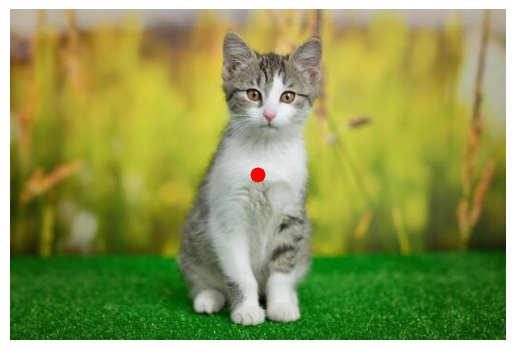

In [3]:
point_img = image.copy()
cv2.circle(point_img, (w // 2, h // 2), 8, (0, 0, 255), -1)
plt.imshow(cv2.cvtColor(point_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 3. Drawing a line

**Syntax:** `cv2.line(img, pt1, pt2, color, thickness)`

For BGR images: `(255,0,0)` is blue, `(0,255,0)` green, `(0,0,255)` red.

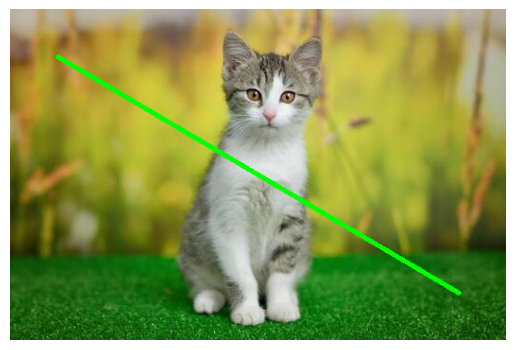

In [4]:
line_img = image.copy()
cv2.line(line_img, (50, 50), (w - 50, h - 50), (0, 255, 0), 3)
plt.imshow(cv2.cvtColor(line_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 4. Drawing a rectangle

**Syntax:** `cv2.rectangle(img, pt1, pt2, color, thickness)`

`thickness=-1` fills the rectangle.

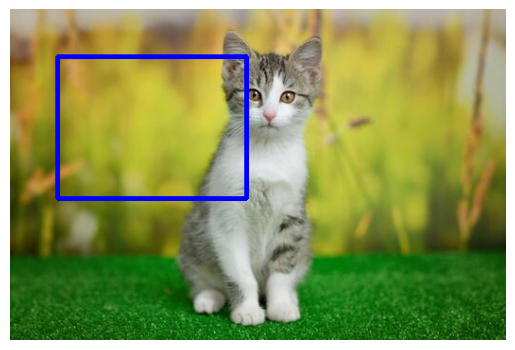

In [5]:
rect_img = image.copy()
cv2.rectangle(rect_img, (50, 50), (250, 200), (255, 0, 0), 3)
plt.imshow(cv2.cvtColor(rect_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


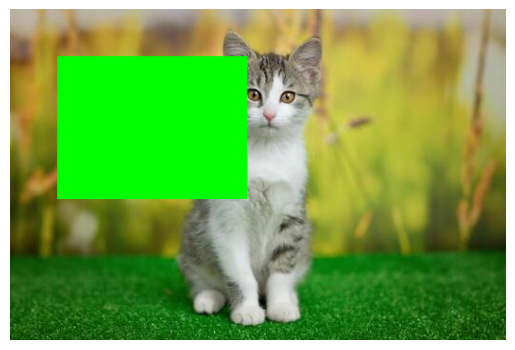

In [6]:
filled = image.copy()
cv2.rectangle(filled, (50, 50), (250, 200), (0, 255, 0), -1)
plt.imshow(cv2.cvtColor(filled, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 5. Drawing a circle

**Syntax:** `cv2.circle(img, center, radius, color, thickness)`

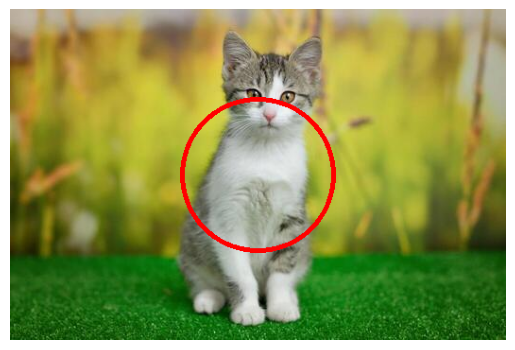

In [7]:
circle_img = image.copy()
cv2.circle(circle_img, (w // 2, h // 2), 80, (0, 0, 255), 4)
plt.imshow(cv2.cvtColor(circle_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 6. Drawing an ellipse

**Syntax:** `cv2.ellipse(img, center, axes, angle, startAngle, endAngle, color, thickness)`

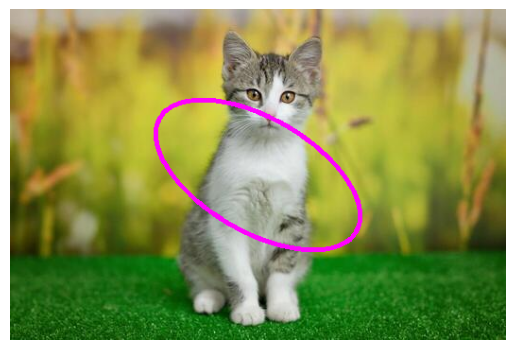

In [8]:
ellipse_img = image.copy()
cv2.ellipse(ellipse_img, (w // 2, h // 2), (120, 60), 30, 0, 360, (255, 0, 255), 3)
plt.imshow(cv2.cvtColor(ellipse_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 7. Drawing a polygon

A polygon is defined by a sequence of `(x, y)` points.

**Syntax:** `cv2.polylines(img, [points], isClosed, color, thickness)`

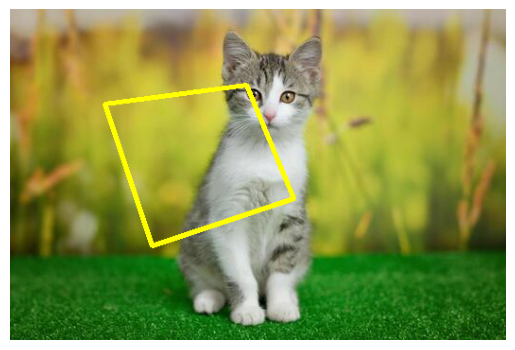

In [9]:
poly_img = image.copy()
points = np.array([[100, 100], [250, 80], [300, 200], [150, 250]], dtype=np.int32)
cv2.polylines(poly_img, [points], True, (0, 255, 255), 4)
plt.imshow(cv2.cvtColor(poly_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 8. Filled polygon

Use `cv2.fillPoly()` when the polygon interior should be filled.

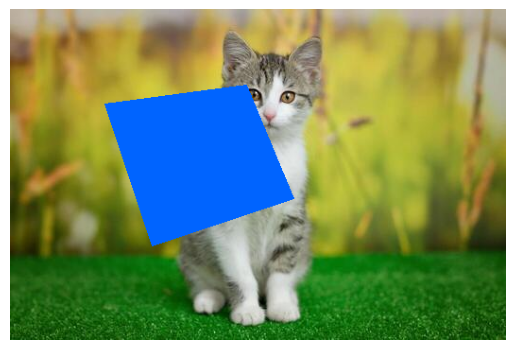

In [10]:
filled_poly = image.copy()
cv2.fillPoly(filled_poly, [points], (255, 100, 0))
plt.imshow(cv2.cvtColor(filled_poly, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 9. Drawing text

**Syntax:** `cv2.putText(img, text, org, fontFace, fontScale, color, thickness)`

`org` is the **bottom-left corner** of the text.

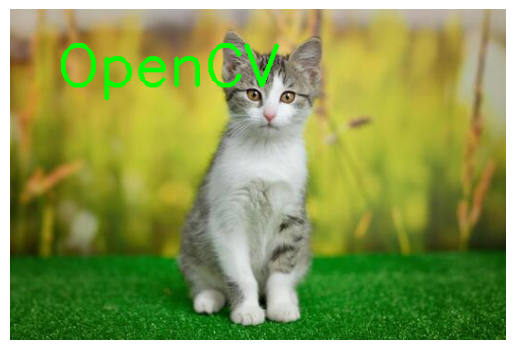

In [11]:
text_img = image.copy()
cv2.putText(text_img, "OpenCV", (50, 80), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 255, 0), 3)
plt.imshow(cv2.cvtColor(text_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 10. Anti-aliased drawing

Use `cv2.LINE_AA` for smoother lines and text edges.

This is useful for clean visual annotations.

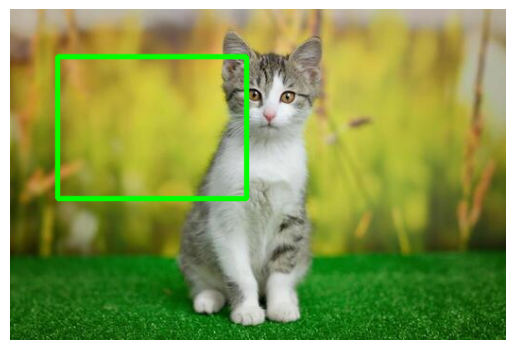

In [12]:
aa_img = image.copy()
cv2.rectangle(aa_img, (50, 50), (250, 200), (0, 255, 0), 3, cv2.LINE_AA)
plt.imshow(cv2.cvtColor(aa_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 11. Bounding-box annotation

A common CV workflow is:

**prediction → `(x1, y1, x2, y2)` → rectangle → label**

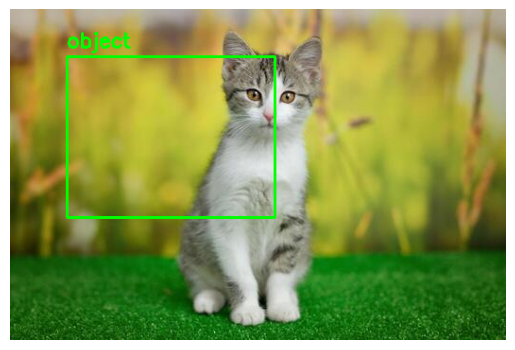

In [13]:
bbox_img = image.copy()
x1, y1, x2, y2 = 60, 50, 280, 220
label = "object"
cv2.rectangle(bbox_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
cv2.putText(bbox_img, label, (x1, max(y1 - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
plt.imshow(cv2.cvtColor(bbox_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 12. Confidence label

Detection models often return a confidence value such as `0.94`.

Format it before drawing so the annotation stays readable.

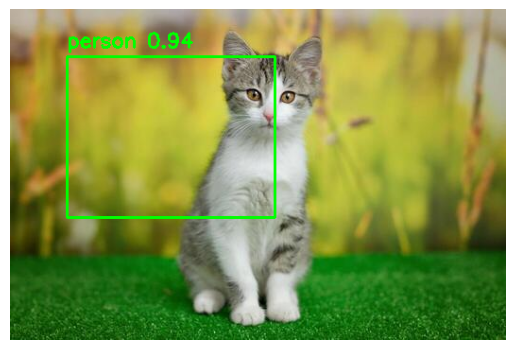

In [14]:
confidence_img = image.copy()
confidence = 0.94
label = f"person {confidence:.2f}"
cv2.rectangle(confidence_img, (60, 50), (280, 220), (0, 255, 0), 2)
cv2.putText(confidence_img, label, (60, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
plt.imshow(cv2.cvtColor(confidence_img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 13. Drawing multiple detections

Store detections as `(x1, y1, x2, y2, label, confidence)` and loop through them.

This is the basic idea behind visualizing YOLO predictions.

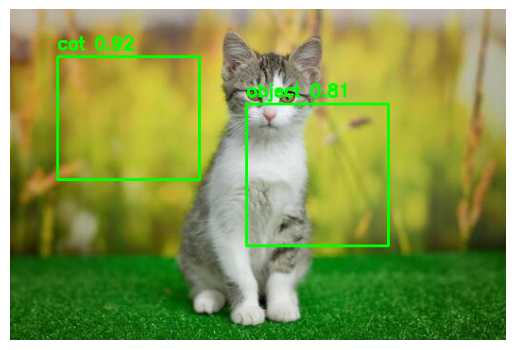

In [15]:
detections = [(50, 50, 200, 180, "cat", 0.92), (250, 100, 400, 250, "object", 0.81)]
multi = image.copy()
for x1, y1, x2, y2, label, conf in detections:
    cv2.rectangle(multi, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(multi, f"{label} {conf:.2f}", (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
plt.imshow(cv2.cvtColor(multi, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 14. Transparent overlays

`cv2.addWeighted()` combines two images:

\[output = \alpha A + \beta B + \gamma\]

For example, `0.7 * image + 0.3 * overlay` creates a transparent annotation layer.

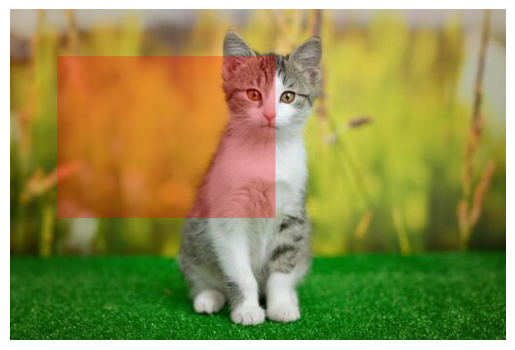

In [16]:
overlay = image.copy()
cv2.rectangle(overlay, (50, 50), (280, 220), (0, 0, 255), -1)
blended = cv2.addWeighted(image, 0.7, overlay, 0.3, 0)
plt.imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 15. Reusable annotation function

Reusable functions make detection visualization cleaner and easier to reuse.

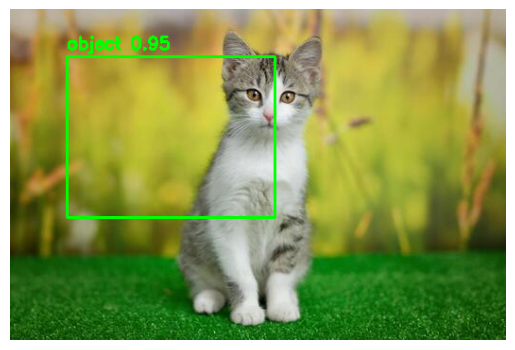

In [17]:
def draw_box(image, box, label=None, color=(0, 255, 0), thickness=2):
    x1, y1, x2, y2 = map(int, box)
    output = image.copy()
    cv2.rectangle(output, (x1, y1), (x2, y2), color, thickness)
    if label:
        cv2.putText(output, label, (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return output

result = draw_box(image, (60, 50, 280, 220), "object 0.95")
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


## 16. Function cheat sheet

| Function | Purpose |
|---|---|
| `cv2.line()` | Draw line |
| `cv2.rectangle()` | Draw rectangle |
| `cv2.circle()` | Draw circle |
| `cv2.ellipse()` | Draw ellipse |
| `cv2.polylines()` | Draw polygon outline |
| `cv2.fillPoly()` | Fill polygon |
| `cv2.putText()` | Draw text |
| `cv2.addWeighted()` | Blend images |
| `cv2.LINE_AA` | Anti-aliased drawing |